In [1]:
import pandas as pd

df = pd.read_csv(r'..\data\W158_select_nan_recode.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n

In [2]:
dep_var_list = [
    'CONF_a_W158_r',
    'CONF_b_W158_r',
    'CONF_c_W158_r',
    'CONF_d_W158_r',
    'CONF_e_W158_r',
    'CONF_i_W158_r',
    'CONF_j_W158_r'
    ]

print(dep_var_list)

['CONF_a_W158_r', 'CONF_b_W158_r', 'CONF_c_W158_r', 'CONF_d_W158_r', 'CONF_e_W158_r', 'CONF_i_W158_r', 'CONF_j_W158_r']


In [3]:
# Dependent variable labels
dep_labels = {
    'CONF_a_W158_r': 'Elected officials',
    'CONF_b_W158_r': 'Journalists',
    'CONF_c_W158_r': 'The military',
    'CONF_d_W158_r': 'Religious leaders',
    'CONF_e_W158_r': 'Business leaders',
    'CONF_i_W158_r': 'Public school principals',
    'CONF_j_W158_r': 'Police officers',
    }

print(dep_labels)

{'CONF_a_W158_r': 'Elected officials', 'CONF_b_W158_r': 'Journalists', 'CONF_c_W158_r': 'The military', 'CONF_d_W158_r': 'Religious leaders', 'CONF_e_W158_r': 'Business leaders', 'CONF_i_W158_r': 'Public school principals', 'CONF_j_W158_r': 'Police officers'}


In [4]:
# Imputation and Scaling

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(df[dep_var_list])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

In [5]:
pd.DataFrame(X_scaled).describe()

,0,1,2,3,4,5,6
count,9.593000e+03,9.593000e+03,9.593000e+03,9.593000e+03,9.593000e+03,9.593000e+03,9593.000000
mean,3.496051e-16,-2.073929e-17,-1.066592e-16,1.659143e-16,-1.836908e-16,-1.762839e-16,0.000000
std,1.000052e+00,1.000052e+00,1.000052e+00,1.000052e+00,1.000052e+00,1.000052e+00,1.000052
min,-1.751441e+00,-1.544224e+00,-2.685711e+00,-1.820828e+00,-1.796884e+00,-2.387616e+00,-2.455138
25%,-3.145494e-01,-3.961389e-01,-1.277259e-01,-6.458512e-01,-4.265438e-01,-1.107969e+00,0.084998
50%,-3.145494e-01,-3.961389e-01,-1.277259e-01,5.291252e-01,-4.265438e-01,1.716778e-01,0.084998
75%,1.122342e+00,7.519459e-01,1.151267e+00,5.291252e-01,9.437961e-01,1.716778e-01,0.084998
max,2.559234e+00,1.900031e+00,1.151267e+00,1.704102e+00,2.314136e+00,1.451325e+00,1.355066


In [6]:
df[dep_var_list].describe()

,CONF_a_W158_r,CONF_b_W158_r,CONF_c_W158_r,CONF_d_W158_r,CONF_e_W158_r,CONF_i_W158_r,CONF_j_W158_r
count,9564.000000,9580.000000,9575.000000,9568.000000,9573.000000,9568.000000,9581.000000
mean,2.219573,2.345511,3.100052,2.548495,2.311919,2.865489,2.932992
std,0.696933,0.871559,0.782629,0.851925,0.730407,0.782497,0.787890
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,3.000000
50%,2.000000,2.000000,3.000000,3.000000,2.000000,3.000000,3.000000
75%,3.000000,3.000000,4.000000,3.000000,3.000000,3.000000,3.000000
max,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000


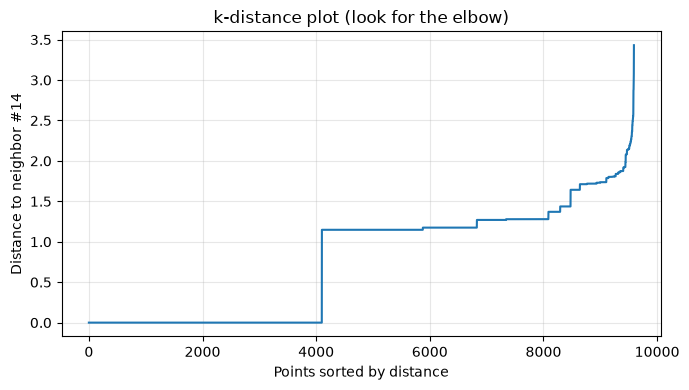

k-distance percentiles (candidate eps values):
  80th percentile: 1.279
  90th percentile: 1.643
  95th percentile: 1.788
  99th percentile: 2.143


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler


# ---------------------------------------------------------------
# 2. min_samples: common starting point is 2 * n_features
# ---------------------------------------------------------------
n_samples, n_features = X_scaled.shape
min_samples = 2 * n_features  # 14 for 7 features

# ---------------------------------------------------------------
# 3. k-distance plot to pick eps
#    Look for the "elbow": where the curve bends sharply upward.
# ---------------------------------------------------------------
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to neighbor #{min_samples}")
plt.title("k-distance plot (look for the elbow)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Optional: eyeball starting candidates from the distribution
print("k-distance percentiles (candidate eps values):")
for p in (80, 90, 95, 99):
    print(f"  {p}th percentile: {np.percentile(k_dist, p):.3f}")



In [8]:
# ---------------------------------------------------------------
# 4. Fit DBSCAN  (set EPS from the elbow you see above)
# ---------------------------------------------------------------
EPS = 1.4

db = DBSCAN(eps=EPS, min_samples=min_samples, n_jobs=-1).fit(X_scaled)
labels = db.labels_  # -1 means noise

# ---------------------------------------------------------------
# 5. Summarize and evaluate
# ---------------------------------------------------------------
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())

print(f"\neps={EPS:.3f}, min_samples={min_samples}")
print(f"Clusters found: {n_clusters}")
print(f"Noise points:   {n_noise} ({n_noise / n_samples:.1%})")
print("Cluster sizes:")
print(pd.Series(labels).value_counts().sort_index().to_string())

mask = labels != -1
if n_clusters >= 2:
    score = silhouette_score(X_scaled[mask], labels[mask],
                             sample_size=min(5000, int(mask.sum())),
                             random_state=42)
    print(f"Silhouette (non-noise points): {score:.3f}")
else:
    print("Silhouette skipped: need at least 2 clusters.")


eps=1.400, min_samples=14
Clusters found: 4
Noise points:   442 (4.6%)
Cluster sizes:
-1     442
 0    4930
 1    1174
 2    2972
 3      75
Silhouette (non-noise points): 0.094


In [9]:


# ---------------------------------------------------------------
# 6. Small parameter sweep
# ---------------------------------------------------------------
rows = []
for ms in (n_features + 1, 2 * n_features, 3 * n_features):
    for eps in np.linspace(np.percentile(k_dist, 50),
                           np.percentile(k_dist, 99), 6):
        lab = DBSCAN(eps=eps, min_samples=ms, n_jobs=-1).fit_predict(X_scaled)
        k = len(set(lab)) - (1 if -1 in lab else 0)
        rows.append({"min_samples": ms, "eps": round(eps, 3),
                     "clusters": k,
                     "noise_pct": round((lab == -1).mean() * 100, 1)})

print("\nParameter sweep:")
print(pd.DataFrame(rows).to_string(index=False))



Parameter sweep:
 min_samples   eps  clusters  noise_pct
           8 1.148       238       25.6
           8 1.347        14        4.2
           8 1.546         1        2.0
           8 1.745         1        0.7
           8 1.944         1        0.2
           8 2.143         1        0.1
          14 1.148       135       36.6
          14 1.347        14        6.6
          14 1.546         1        3.0
          14 1.745         1        0.9
          14 1.944         1        0.2
          14 2.143         1        0.1
          21 1.148        89       44.8
          21 1.347        13        9.9
          21 1.546         1        4.5
          21 1.745         1        1.2
          21 1.944         1        0.3
          21 2.143         1        0.1


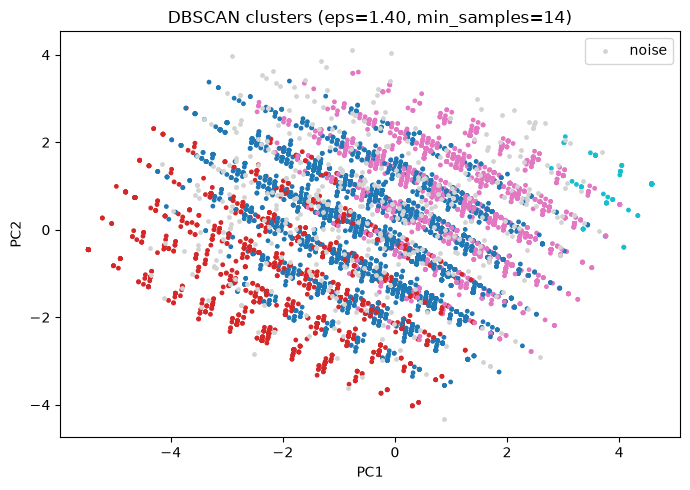


Cluster means per feature:
            f1     f2     f3     f4     f5     f6     f7
cluster                                                 
-1       0.180  0.149 -0.290 -0.303 -0.163 -0.135 -0.564
 0      -0.315 -0.129 -0.064 -0.039 -0.089 -0.063 -0.040
 1      -1.751 -0.869 -0.565 -0.424 -0.563 -0.843 -0.360
 2       1.122  0.497  0.344  0.242  0.351  0.425  0.262
 3       2.559  1.517  1.134  1.375  1.675  1.298  1.220


In [10]:

# ---------------------------------------------------------------
# 7. Visualize in 2D with PCA (for display only; clustering used all 7 features)
# ---------------------------------------------------------------
X2 = PCA(n_components=2, random_state=42).fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X2[mask, 0], X2[mask, 1], c=labels[mask], s=6, cmap="tab10")
plt.scatter(X2[~mask, 0], X2[~mask, 1], c="lightgray", s=6, label="noise")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"DBSCAN clusters (eps={EPS:.2f}, min_samples={min_samples})")
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 8. Attach labels back to your data and profile clusters
# ---------------------------------------------------------------
df = pd.DataFrame(X_scaled, columns=[f"f{i + 1}" for i in range(n_features)])
df["cluster"] = labels
print("\nCluster means per feature:")
print(df.groupby("cluster").mean().round(3).to_string())

In [11]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

labels = DBSCAN(eps=1.4, min_samples=14).fit_predict(X_scaled)  # tune eps and min_samples

mask = labels != -1                      # non-noise points only
n_clusters = len(set(labels[mask]))

print("DBScan solution")
print()
print(f"Clusters found:    {n_clusters}")
print(f"Noise fraction:    {(~mask).mean():.3f}")

if n_clusters >= 1:
    sizes = np.bincount(labels[mask]) / len(labels) * 100   # % of total points
    print(f"Smallest cluster:  {sizes.min():.1f}% of total")
    print(f"Largest cluster:   {sizes.max():.1f}% of total")

if n_clusters >= 2:                      # indices require at least 2 clusters
    print(f"Silhouette:        {silhouette_score(X_scaled[mask], labels[mask]):.3f}")
    print(f"Davies-Bouldin:    {davies_bouldin_score(X_scaled[mask], labels[mask]):.3f}")
    print(f"Calinski-Harabasz: {calinski_harabasz_score(X_scaled[mask], labels[mask]):.1f}")
else:
    print("Fewer than 2 clusters found; indices not computable. Adjust eps or min_samples.")

DBScan solution

Clusters found:    4
Noise fraction:    0.046
Smallest cluster:  0.8% of total
Largest cluster:   51.4% of total
Silhouette:        0.095
Davies-Bouldin:    2.002
Calinski-Harabasz: 963.7


In [12]:
mask = labels != -1                      # non-noise points only
n_clusters = len(set(labels[mask]))

print("DBScan solution")
print()
print(f"Clusters found:    {n_clusters}")
print(f"Noise fraction:    {(~mask).mean():.3f}")

if n_clusters >= 1:
    sizes = np.bincount(labels[mask]) / len(labels) * 100   # % of total points
    print(f"Smallest cluster:  {sizes.min():.1f}% of total")
    print(f"Largest cluster:   {sizes.max():.1f}% of total")

if n_clusters >= 2:                      # indices require at least 2 clusters
    print(f"Silhouette:        {silhouette_score(X_scaled[mask], labels[mask]):.3f}")
    print(f"Davies-Bouldin:    {davies_bouldin_score(X_scaled[mask], labels[mask]):.3f}")
    print(f"Calinski-Harabasz: {calinski_harabasz_score(X_scaled[mask], labels[mask]):.1f}")
else:
    print("Fewer than 2 clusters found; indices not computable. Adjust eps or min_samples.")

DBScan solution

Clusters found:    4
Noise fraction:    0.046
Smallest cluster:  0.8% of total
Largest cluster:   51.4% of total
Silhouette:        0.095
Davies-Bouldin:    2.002
Calinski-Harabasz: 963.7
